In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/processed/cleaned_reviews.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (22641, 14)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Sentiment,Combined_Review,Cleaned_Review,Processed_Review
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,Positive,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,absolutely wonderful silky sexy comfortable
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,Positive,Love this dress! it's sooo pretty. i happene...,love this dress its sooo pretty i happened to ...,love dress sooo pretty happened find store im ...
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,Neutral,Some major design flaws I had such high hopes ...,some major design flaws i had such high hopes ...,major design flaw high hope dress really wante...
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,Positive,"My favorite buy! I love, love, love this jumps...",my favorite buy i love love love this jumpsuit...,favorite buy love love love jumpsuit fun flirt...
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,Positive,Flattering shirt This shirt is very flattering...,flattering shirt this shirt is very flattering...,flattering shirt shirt flattering due adjustab...


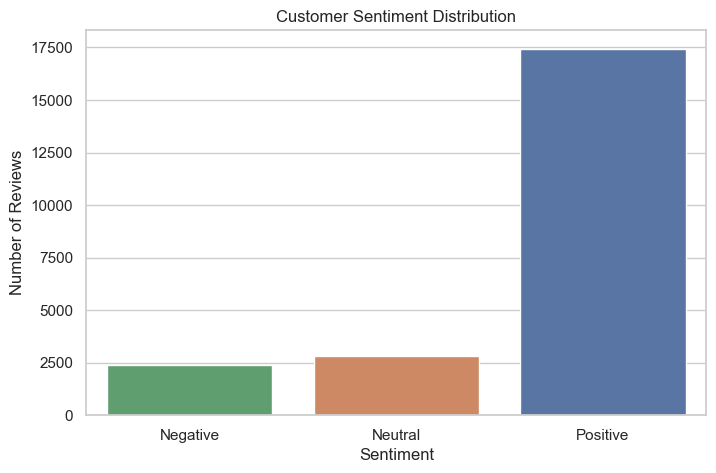

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Sentiment',
    hue='Sentiment',
    order=['Negative', 'Neutral', 'Positive'],
    legend=False
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

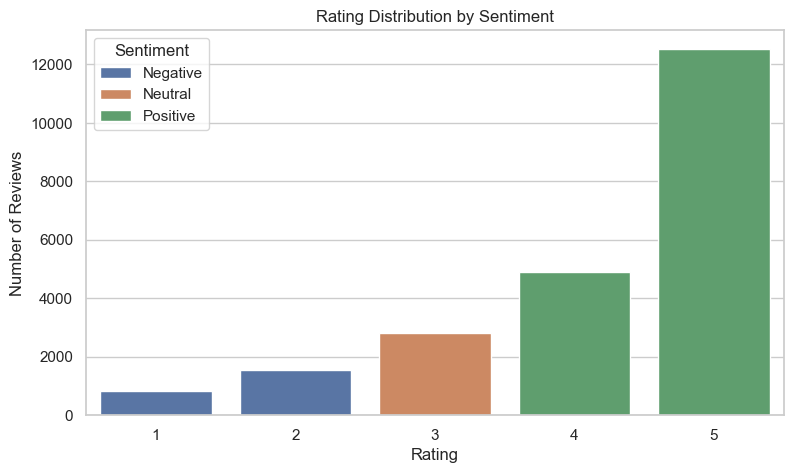

In [22]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Rating',
    hue='Sentiment'
)

plt.title("Rating Distribution by Sentiment")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

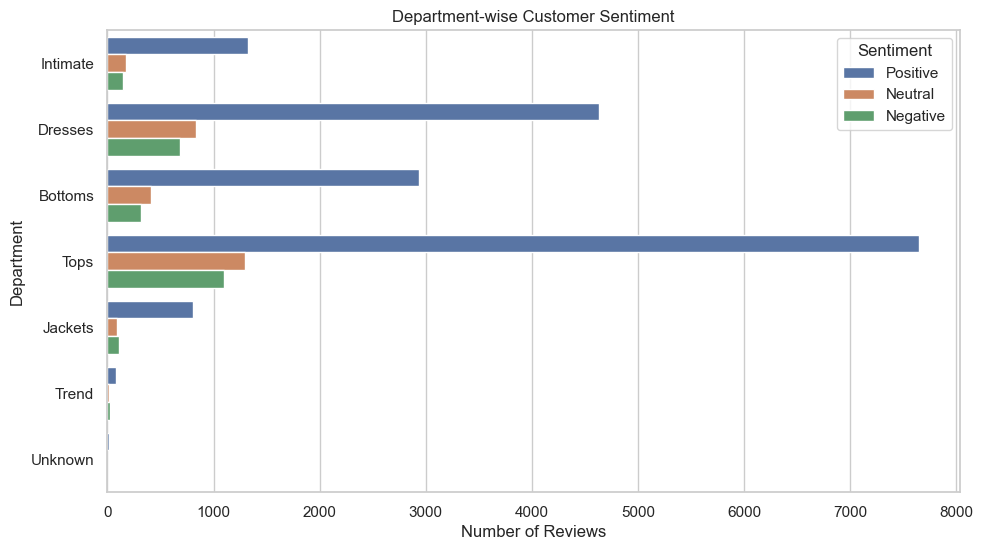

In [23]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y='Department Name',
    hue='Sentiment'
)

plt.title("Department-wise Customer Sentiment")
plt.xlabel("Number of Reviews")
plt.ylabel("Department")

plt.show()

# Most Frequently Used Words

In [24]:
all_words = ' '.join(
    df['Processed_Review'].dropna()
).split()

word_counts = Counter(all_words)

most_common_words = word_counts.most_common(20)

word_freq_df = pd.DataFrame(
    most_common_words,
    columns=['Word', 'Frequency']
)

display(word_freq_df)

,Word,Frequency
0,not,19432
1,dress,13100
2,love,10878
3,fit,10868
4,size,9670
5,top,9554
6,great,7907
7,color,7449
8,like,7414
9,look,7117


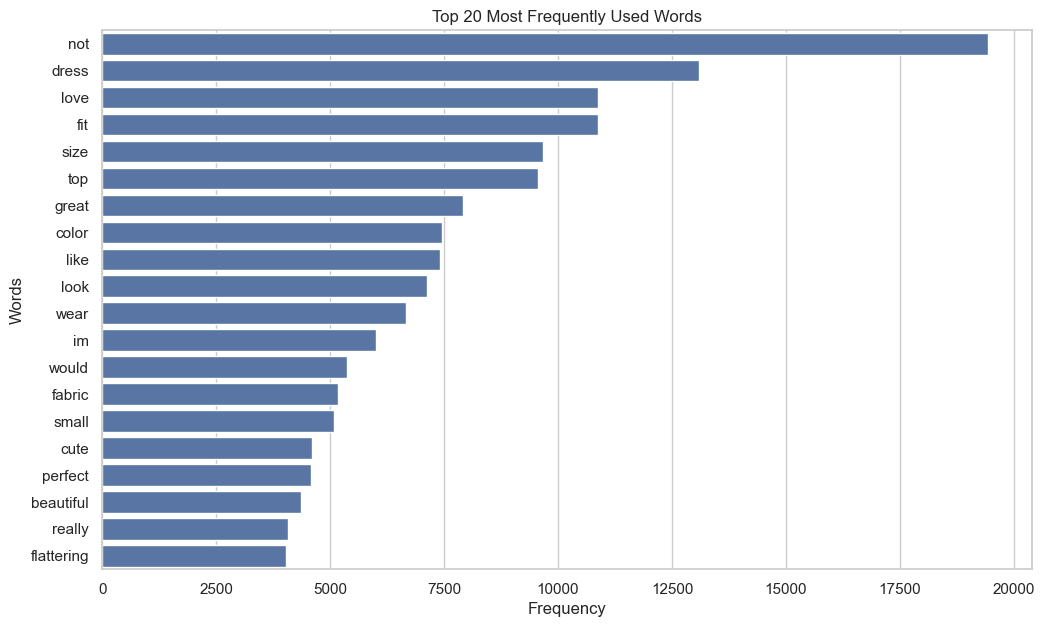

In [25]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_freq_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 20 Most Frequently Used Words")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

In [26]:
positive_reviews = df[df['Sentiment'] == 'Positive']
negative_reviews = df[df['Sentiment'] == 'Negative']
neutral_reviews = df[df['Sentiment'] == 'Neutral']

print("Positive reviews:", len(positive_reviews))
print("Negative reviews:", len(negative_reviews))
print("Neutral reviews:", len(neutral_reviews))

Positive reviews: 17448
Negative reviews: 2370
Neutral reviews: 2823


In [27]:
positive_words = ' '.join(
    positive_reviews['Processed_Review'].dropna()
).split()

positive_freq = Counter(positive_words)

positive_top20 = pd.DataFrame(
    positive_freq.most_common(20),
    columns=['Word', 'Frequency']
)

positive_top20

,Word,Frequency
0,not,13012
1,dress,10229
2,love,9481
3,fit,8632
4,size,7740
5,top,7266
6,great,7040
7,color,5973
8,wear,5572
9,look,5090


In [28]:
negative_words = ' '.join(
    negative_reviews['Processed_Review'].dropna()
).split()

negative_freq = Counter(negative_words)

negative_top20 = pd.DataFrame(
    negative_freq.most_common(20),
    columns=['Word', 'Frequency']
)

negative_top20

,Word,Frequency
0,not,2916
1,dress,1273
2,like,1143
3,look,961
4,top,955
5,fit,898
6,fabric,796
7,would,792
8,size,785
9,back,629


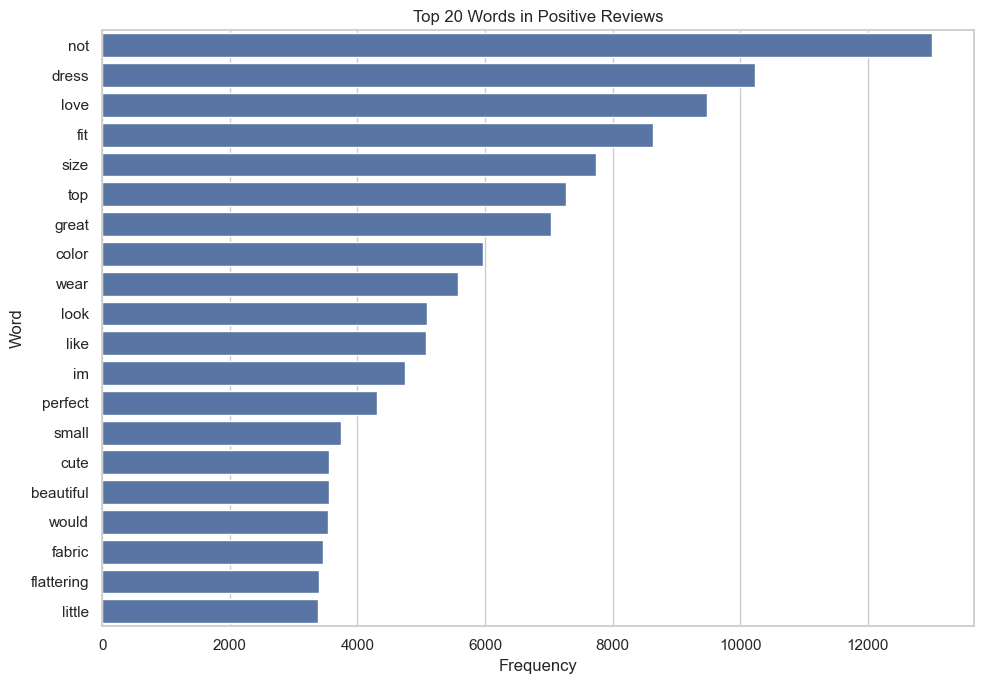

In [29]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=positive_top20,
    x='Frequency',
    y='Word'
)

plt.title('Top 20 Words in Positive Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

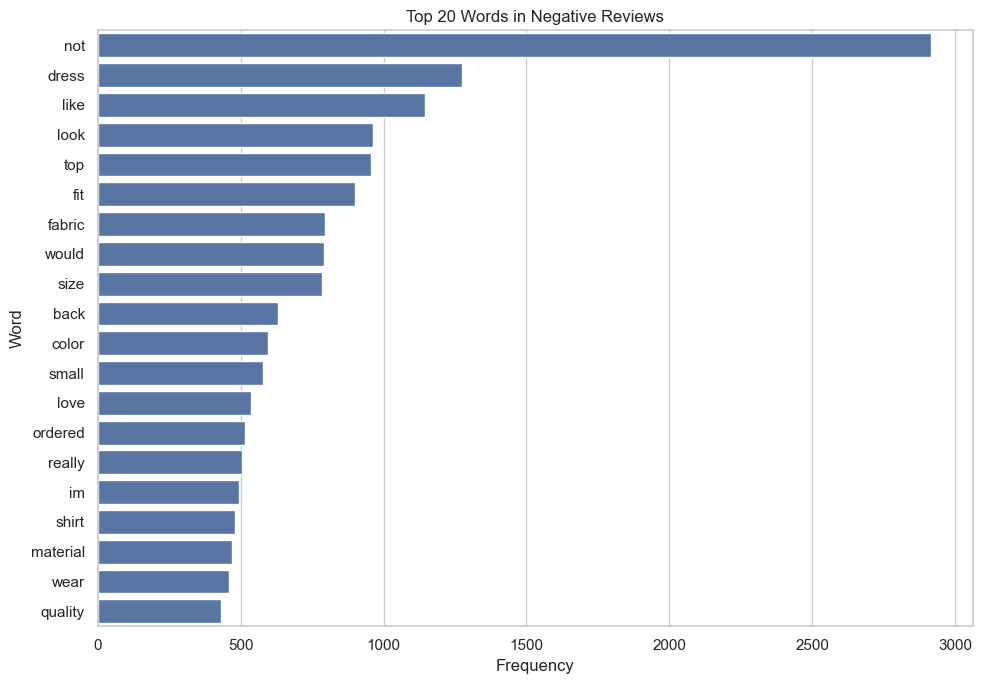

In [30]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=negative_top20,
    x='Frequency',
    y='Word'
)

plt.title('Top 20 Words in Negative Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

# Department-wise Sentiment Distribution

In [31]:
department_sentiment = pd.crosstab(
    df['Department Name'],
    df['Sentiment']
)

department_sentiment

Sentiment,Negative,Neutral,Positive
Department Name,,,
Bottoms,317,407,2938
Dresses,681,830,4634
Intimate,147,177,1329
Jackets,108,90,804
Tops,1096,1300,7652
Trend,21,19,78
Unknown,0,0,13


In [32]:
department_percentage = pd.crosstab(
    df['Department Name'],
    df['Sentiment'],
    normalize='index'
) * 100

department_percentage.round(2)

Sentiment,Negative,Neutral,Positive
Department Name,,,
Bottoms,8.66,11.11,80.23
Dresses,11.08,13.51,75.41
Intimate,8.89,10.71,80.40
Jackets,10.78,8.98,80.24
Tops,10.91,12.94,76.15
Trend,17.80,16.10,66.10
Unknown,0.00,0.00,100.00


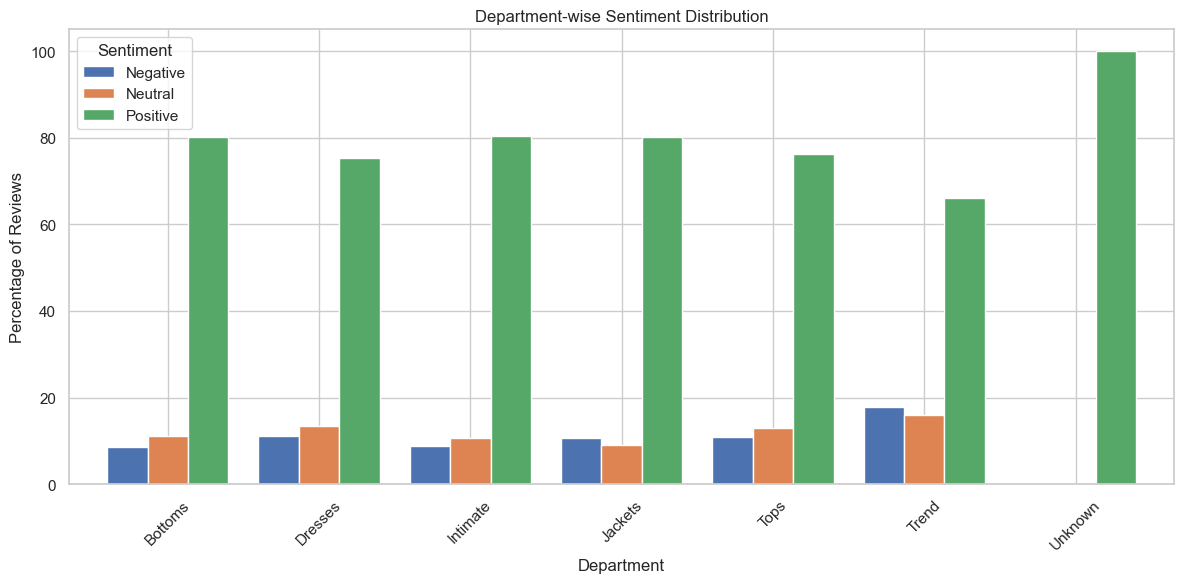

In [33]:
department_percentage.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Department-wise Sentiment Distribution')
plt.xlabel('Department')
plt.ylabel('Percentage of Reviews')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

# Age-wise Sentiment Analysis

In [ ]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 64, 100],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-64',
        '65+'
    ]
)

df[['Age', 'Age Group']].head(10)

,Age,Age Group
0,33,26-35
1,34,26-35
2,60,56-65
3,50,46-55
4,47,46-55
5,49,46-55
6,39,36-45
7,39,36-45
8,24,18-25
9,34,26-35


In [35]:
age_sentiment = pd.crosstab(
    df['Age Group'],
    df['Sentiment'],
    normalize='index'
) * 100

age_sentiment.round(2)

Sentiment,Negative,Neutral,Positive
Age Group,,,
18-25,7.83,11.54,80.62
26-35,11.76,14.07,74.17
36-45,10.26,12.89,76.85
46-55,10.83,12.07,77.10
56-65,9.26,10.49,80.25
65+,9.80,10.02,80.18


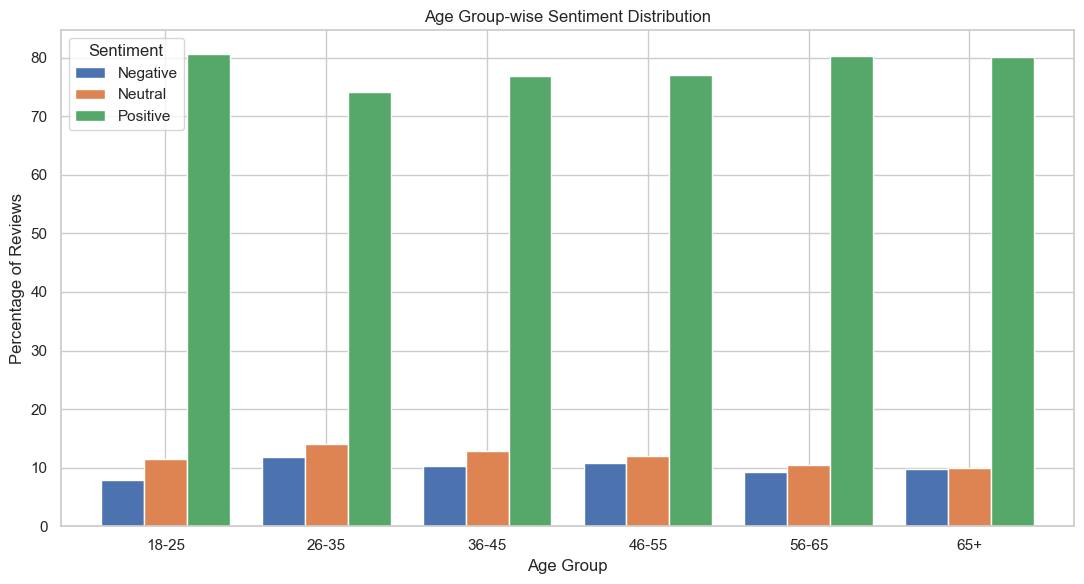

In [36]:
age_sentiment.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Age Group-wise Sentiment Distribution')
plt.xlabel('Age Group')
plt.ylabel('Percentage of Reviews')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

In [37]:
age_rating = df.groupby('Age Group', observed=False)['Rating'].mean()

age_rating

Age Group
18-25    4.287279
26-35    4.117786
36-45    4.176512
46-55    4.162840
56-65    4.285094
65+      4.261606
Name: Rating, dtype: float64

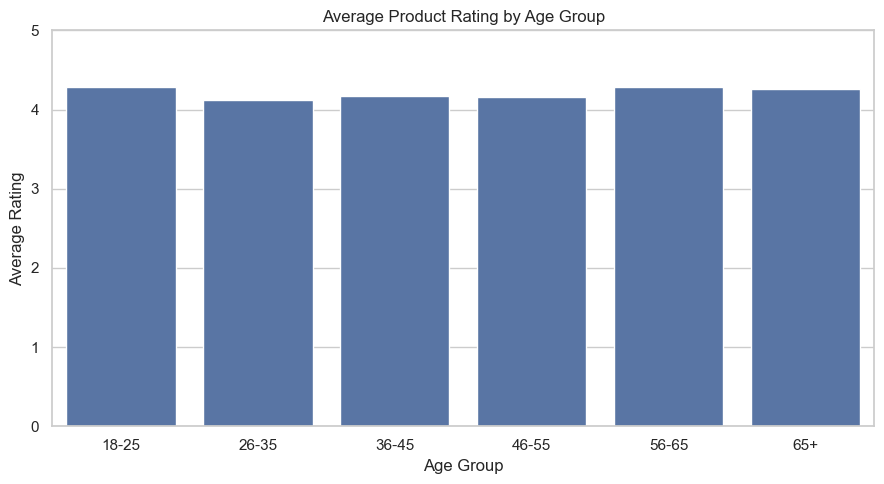

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_rating.index,
    y=age_rating.values
)

plt.title('Average Product Rating by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Rating')
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

# Exploratory Data Analysis – Key Findings

1. The dataset contains 22,641 customer reviews.
2. Positive reviews account for approximately 77% of the dataset, indicating a strong positive sentiment imbalance.
3. Commonly discussed product aspects include fit, size, color, fabric, and material.
4. Positive reviews frequently contain words such as love, great, perfect, beautiful, and soft.
5. Negative reviews frequently contain words related to fabric, material, quality, and sizing.
6. Tops has the highest review volume among all departments.
7. Intimate has the highest positive sentiment percentage among the major departments.
8. Customers aged 56–65 have the highest average rating (4.30).
9. Customers aged 26–35 have the lowest average rating (4.12) and highest negative sentiment percentage.